# AI Security Monitor — Machine Learning and NLP

**Goal:** build an educational prototype that detects unusual network traffic and classifies HTTP requests as `Normal`, `SQL Injection`, or `XSS`.

Run the cells from top to bottom. This notebook uses the provided project ZIP and synthetic demo data if real datasets are not available. Synthetic results are for demonstrating the workflow only; they are not evidence of real-world security performance.

## 1. Upload and extract the project ZIP
Upload `ai_security_monitor 7.zip` when prompted.

In [ ]:
from google.colab import files
uploaded = files.upload()  # Select ai_security_monitor 7.zip

import os, zipfile
zip_name = next((name for name in uploaded if name.lower().endswith('.zip')), None)
if zip_name is None:
    raise ValueError("Please upload the project ZIP file.")

with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall('/content')

PROJECT_DIR = '/content/ai_security_monitor'
os.chdir(PROJECT_DIR)
print("Project folder:", os.getcwd())
print("Files:", os.listdir(PROJECT_DIR)[:10])

Saving ai_security_monitor 7.zip to ai_security_monitor 7.zip
Project folder: /content/ai_security_monitor
Files: ['src', 'notebooks', 'pytest.ini', 'docs', 'train_all.py', 'app.py', 'data', 'requirements.txt', 'scripts', 'config.py']


## 2. Install required libraries

In [ ]:
%pip -q install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 75.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 100.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 51.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.5/947.5 kB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 45.4 MB/s eta 0:00:00


## 3. Generate the network dataset
This creates a synthetic dataset with normal traffic and several simulated attack categories. Use CIC-IDS2017 instead if your instructor requires real network data.

In [ ]:
!python scripts/generate_network_data.py

import pandas as pd
network_df = pd.read_csv('data/network_traffic.csv')
print("Dataset shape:", network_df.shape)
display(network_df.head())
print("\nTraffic labels:")
display(network_df['Label'].value_counts().to_frame('count'))

Сетевые данные записаны в /content/ai_security_monitor/data
Dataset shape: (12240, 16)


,Timestamp,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Mean,Bwd Packet Length Mean,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,SYN Flag Count,ACK Flag Count,Average Packet Size,Label
0,2026-09-01 08:00:03,123,32318.0,9,7,431.4,3158.7,47.94,451.25,111090.72,495.09,2154.50,0,1,224.39,BENIGN
1,2026-09-01 08:00:07,27865,33.0,1,0,2.0,0.0,2.03,0.00,61026.42,30018.96,33.31,1,1,2.03,PortScan
2,2026-09-01 08:00:23,8080,1931.0,11,6,408.8,467.2,37.16,77.87,453768.93,8805.92,120.66,0,0,51.53,BENIGN
3,2026-09-01 08:00:25,443,9641.0,12,5,575.0,338.3,47.92,67.66,94736.88,1763.30,602.56,0,1,53.73,BENIGN
4,2026-09-01 08:00:32,22,892521.0,34,44,1442.8,5265.3,42.43,119.67,7515.90,87.39,11591.19,0,1,86.00,SSH-Patator



Traffic labels:


,count
Label,
BENIGN,9056
DoS Hulk,1096
PortScan,979
DDoS,733
SSH-Patator,376


## 4. Explore network data quality

Rows: 12240
Columns: 16
Duplicate rows: 240
Missing values: 124
Infinite values: 123


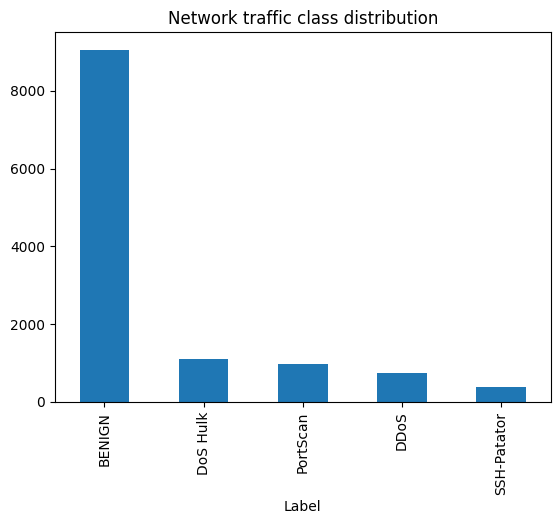

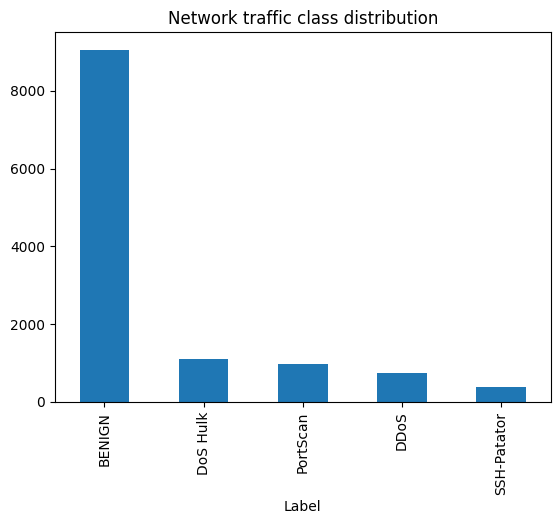

In [ ]:
import numpy as np
df = pd.read_csv('data/network_traffic.csv', low_memory=False)
df.columns = df.columns.str.strip()
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", int(df.isna().sum().sum()))
print("Infinite values:", int(np.isinf(df.select_dtypes(include='number')).sum().sum()))
display(df['Label'].value_counts().plot(kind='bar', title='Network traffic class distribution').figure)

## 5. Create a small three-class HTTP dataset
The technical specification expects `request` and `label` columns. This fallback dataset is synthetic and intended to verify that the pipeline runs. For the final research results, replace it with a properly labeled open dataset.

In [ ]:
import random
random.seed(42)

normal_templates = [
    "GET /home HTTP/1.1", "GET /products HTTP/1.1", "GET /about-us HTTP/1.1",
    "GET /contact HTTP/1.1", "GET /search?q=books HTTP/1.1",
    "GET /category/electronics HTTP/1.1", "POST /login username=alex",
    "GET /profile?id=15 HTTP/1.1", "GET /news/latest HTTP/1.1",
    "GET /help/faq HTTP/1.1", "GET /cart HTTP/1.1", "POST /checkout item=phone",
    "GET /images/logo.png HTTP/1.1", "GET /blog/article HTTP/1.1",
    "GET /search?q=wireless+headphones HTTP/1.1", "GET /language?code=en HTTP/1.1",
    "POST /feedback message=great service", "GET /products?sort=price HTTP/1.1",
    "GET /account/settings HTTP/1.1", "GET /offers/summer HTTP/1.1",
    "GET /catalog?page=2 HTTP/1.1", "POST /register email=user@example.com",
    "GET /support/ticket HTTP/1.1", "GET /weather?city=Almaty HTTP/1.1",
    "GET /events/upcoming HTTP/1.1", "GET /store/phones HTTP/1.1",
    "POST /newsletter email=reader@example.com", "GET /reviews?product=case HTTP/1.1",
    "GET /shipping-info HTTP/1.1", "GET /privacy-policy HTTP/1.1"
]
sqli_templates = [
    "' OR '1'='1", "' OR 1=1 --", "admin'--", "' UNION SELECT username,password FROM users",
    "1; DROP TABLE users", "' AND SLEEP(5)--", "1 UNION SELECT NULL,NULL",
    "' OR 'a'='a' /*", "1' ORDER BY 5--", "'; EXEC xp_cmdshell('dir')",
    "id=1 OR 1=1", "' HAVING 1=1--", "1 AND 1=1", "user' OR 'x'='x",
    "SELECT * FROM users WHERE id='1' OR '1'='1'", "1 UNION ALL SELECT database()",
    "' AND '1'='2", " OR 1=1#", "name=' OR ''='", "1; WAITFOR DELAY '0:0:5'",
    "' UNION SELECT email FROM customers--", "login=admin%27%20--",
    "product=1 AND SUBSTRING(version(),1,1)='5'", "' OR 1=1 LIMIT 1--",
    "1) OR (1=1", "' AND updatexml(1,concat(0x7e,user()),1)--",
    "id=2; SELECT @@version", "' OR EXISTS(SELECT * FROM users)--",
    "1 AND ascii(substring(user(),1,1))>64", "search=' UNION SELECT NULL--"
]
xss_templates = [
    "<script>alert(1)</script>", "<img src=x onerror=alert(1)>",
    "<svg onload=alert(1)>", "<body onload=alert(1)>",
    "<iframe src='javascript:alert(1)'>", "<script>document.cookie</script>",
    "<a href='javascript:alert(1)'>click</a>", "<div onmouseover=alert(1)>",
    "<input onfocus=alert(1) autofocus>", "<svg><script>alert(1)</script></svg>",
    "%3Cscript%3Ealert(1)%3C/script%3E", "&lt;script&gt;alert(1)&lt;/script&gt;",
    "<video><source onerror=alert(1)>", "<details open ontoggle=alert(1)>",
    "<marquee onstart=alert(1)>", "<button onclick=alert(1)>open</button>",
    "<img src='x' onerror='document.location=1'>", "<script>prompt(1)</script>",
    "<div style='background:url(javascript:alert(1))'>", "<math><mtext></script><script>alert(1)</script>",
    "<a onfocus=alert(1) autofocus>link</a>", "<object data='javascript:alert(1)'>",
    "<form><button formaction='javascript:alert(1)'>go</button></form>",
    "<svg onload=confirm(1)>", "<img src=x onerror=prompt(1)>",
    "<script>console.log(document.domain)</script>", "<p onmouseenter=alert(1)>text</p>",
    "<input value='x' onblur=alert(1)>", "<video onerror=alert(1)>",
    "<style>@import 'javascript:alert(1)';</style>"
]

# Add distinct harmless query parameters to expand the demonstration examples.
records = []
for label, templates in [('Normal', normal_templates), ('SQL Injection', sqli_templates), ('XSS', xss_templates)]:
    for i, request in enumerate(templates):
        records.append({'request': request, 'label': label})
        records.append({'request': request + f'&demo={i+100}', 'label': label})

http_df = pd.DataFrame(records).drop_duplicates()
http_df.to_csv('data/http_requests.csv', index=False)
print("HTTP dataset shape:", http_df.shape)
display(http_df.groupby('label').size().to_frame('count'))
display(http_df.sample(6, random_state=42))

HTTP dataset shape: (180, 2)


,count
label,
Normal,60
SQL Injection,60
XSS,60


,request,label
19,GET /help/faq HTTP/1.1&demo=109,Normal
42,POST /register email=user@example.com,Normal
153,<img src='x' onerror='document.location=1'>&de...,XSS
78,'; EXEC xp_cmdshell('dir'),SQL Injection
145,<video><source onerror=alert(1)>&demo=112,XSS
15,GET /profile?id=15 HTTP/1.1&demo=107,Normal


## 6. Train models and evaluate them
The project pipeline cleans the data, splits training/test data, trains Isolation Forest and Random Forest for network traffic, and TF-IDF + Logistic Regression / Naive Bayes for HTTP text. Metrics are calculated on held-out test data.

In [ ]:
!python train_all.py

== Модуль 1: сетевой трафик ==
Качество данных: 240 дубликатов, 124 пропусков, 123 inf
Isolation Forest: accuracy=0.748 f1_macro=0.6692 FPR=0.1649
Random Forest: accuracy=0.9897 f1_macro=0.9774 FPR=0.0032
== Модуль 2: HTTP-запросы (NLP) ==
После очистки: 176 строк, удалено дубликатов: 4
Logistic Regression: accuracy=1.0 f1_macro=1.0 FPR=0.0
Naive Bayes: accuracy=1.0 f1_macro=1.0 FPR=0.0
Метрики сохранены в /content/ai_security_monitor/outputs/reports/metrics.json


## 7. View model metrics

In [ ]:
import json, os
metrics_path = 'outputs/reports/metrics.json'
with open(metrics_path, encoding='utf-8') as f:
    metrics = json.load(f)

def show_metrics(section):
    rows = []
    for model_name, values in metrics.get(section, {}).items():
        if isinstance(values, dict) and 'accuracy' in values:
            rows.append({
                'Model': model_name,
                'Accuracy': values.get('accuracy'),
                'Precision (macro)': values.get('precision_macro'),
                'Recall (macro)': values.get('recall_macro'),
                'F1 (macro)': values.get('f1_macro'),
                'False positive rate': values.get('false_positive_rate')
            })
    return pd.DataFrame(rows)

print("Network model metrics")
display(show_metrics('network'))
print("HTTP / NLP model metrics")
display(show_metrics('nlp'))
print("Saved reports:", os.listdir('outputs/reports'))

Network model metrics


,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),False positive rate
0,isolation_forest,0.7480,0.6710,0.6676,0.6692,0.1649
1,random_forest,0.9897,0.9769,0.9779,0.9774,0.0032


HTTP / NLP model metrics


,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),False positive rate
0,logistic_regression,1.0,1.0,1.0,1.0,0.0
1,naive_bayes,1.0,1.0,1.0,1.0,0.0


Saved reports: ['cm_nlp_naive_bayes.png', 'cm_network_random_forest.png', 'cm_network_isolation_forest.png', 'metrics.json', 'cm_nlp_logistic_regression.png']


## 8. Plot the confusion matrices

cm_network_isolation_forest.png


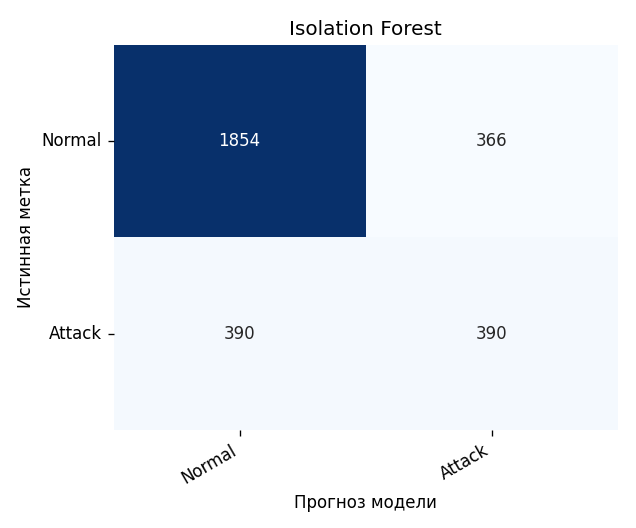

cm_network_random_forest.png


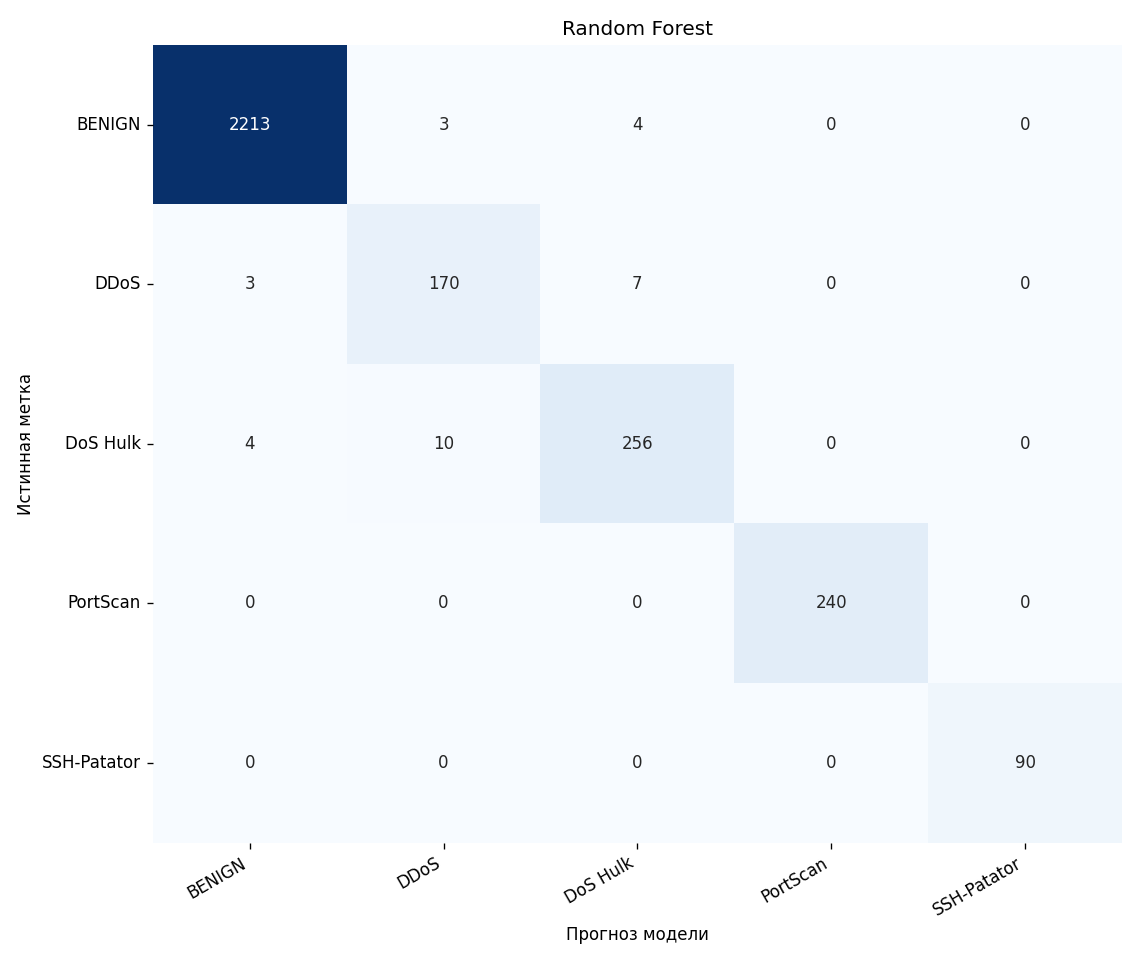

cm_nlp_logistic_regression.png


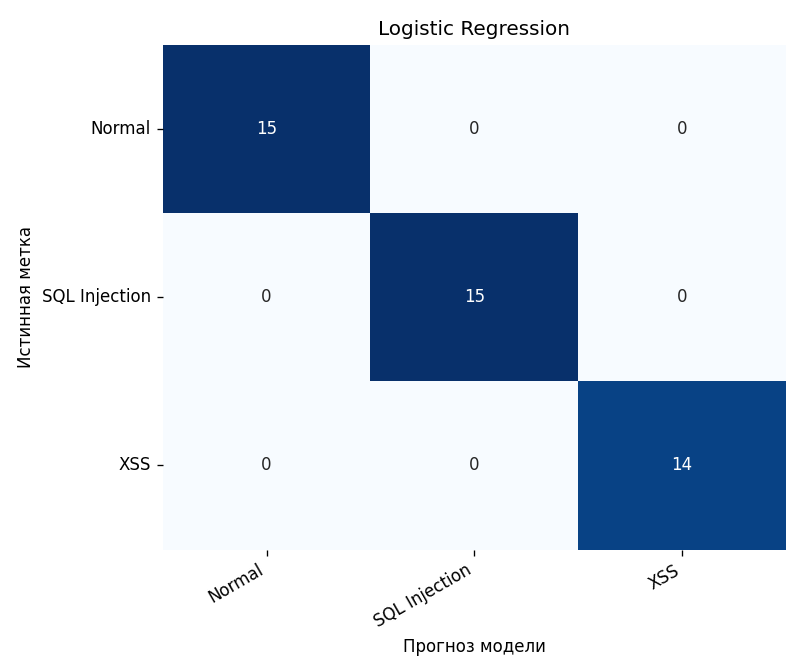

cm_nlp_naive_bayes.png


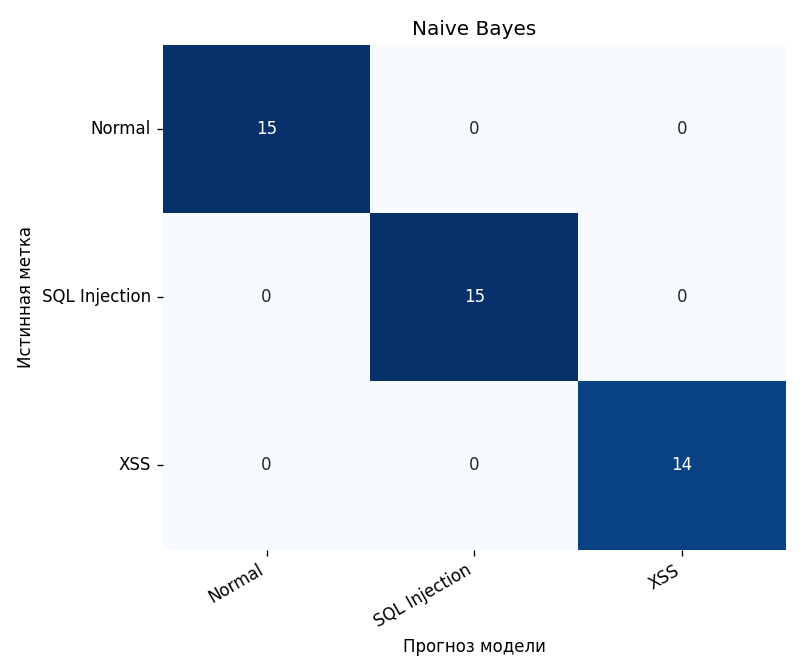

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

for filename in sorted(os.listdir('outputs/reports')):
    if filename.endswith('.png') and filename.startswith('cm_'):
        print(filename)
        display(Image.open(os.path.join('outputs/reports', filename)))

## 9. Test individual HTTP requests
The trained Logistic Regression model returns a predicted class and class probabilities. Treat each output as an unconfirmed model prediction, not proof of an attack.

In [ ]:
from src.nlp.models import train_nlp_models, classify_requests
from src.nlp.preprocess import clean_text_data, load_text_csv
import config

text_df = load_text_csv(config.TEXT_DATA_PATH, require_label=True)
text_df, quality = clean_text_data(text_df)
nlp_models, _ = train_nlp_models(text_df)

test_requests = [
    "GET /products?q=books HTTP/1.1",
    "' OR 1=1 --",
    "<img src=x onerror=alert(1)>",
    "GET /search?q=wireless+headphones HTTP/1.1"
]
predictions = classify_requests(nlp_models['logistic_regression'], pd.Series(test_requests))
display(predictions)

,request,prediction,confidence,prob_Normal,prob_SQL Injection,prob_XSS,needs_review
0,GET /products?q=books HTTP/1.1,Normal,0.8067,0.8067,0.1088,0.0845,False
1,' OR 1=1 --,SQL Injection,0.8603,0.0667,0.8603,0.0730,False
2,<img src=x onerror=alert(1)>,XSS,0.8826,0.0521,0.0653,0.8826,False
3,GET /search?q=wireless+headphones HTTP/1.1,Normal,0.8062,0.8062,0.1088,0.0851,False


## 10. Review generated event files

In [ ]:
for path in ['outputs/network_events.csv', 'outputs/http_events.csv']:
    if os.path.exists(path):
        print("\n", path)
        events = pd.read_csv(path)
        print("Rows:", len(events))
        display(events.head())


 outputs/network_events.csv
Rows: 12000


,event_id,timestamp,source_module,model_name,prediction,score,is_alert,needs_review,ground_truth,details,status
0,net-000001,2026-09-01T08:00:03,network,IsolationForest,Normal,0.3265,False,False,BENIGN,port 123 | fwd_pkts 9 | RF: BENIGN (1.0),Прогноз модели (не подтверждено)
1,net-000002,2026-09-01T08:00:07,network,IsolationForest,Anomaly,0.5732,True,False,PortScan,port 27865 | fwd_pkts 1 | RF: PortScan (1.0),Прогноз модели (не подтверждено)
2,net-000003,2026-09-01T08:00:23,network,IsolationForest,Anomaly,0.4524,True,True,BENIGN,port 8080 | fwd_pkts 11 | RF: BENIGN (0.98),Прогноз модели (не подтверждено)
3,net-000004,2026-09-01T08:00:25,network,IsolationForest,Normal,0.3354,False,False,BENIGN,port 443 | fwd_pkts 12 | RF: BENIGN (1.0),Прогноз модели (не подтверждено)
4,net-000005,2026-09-01T08:00:32,network,IsolationForest,Normal,0.3561,False,True,SSH-Patator,port 22 | fwd_pkts 34 | RF: SSH-Patator (0.99),Прогноз модели (не подтверждено)



 outputs/http_events.csv
Rows: 176


,event_id,timestamp,source_module,model_name,prediction,score,is_alert,needs_review,ground_truth,details,status
0,http-000001,NaN,http,LogisticRegression,Normal,0.8635,False,False,Normal,GET /home HTTP/1.1,Прогноз модели (не подтверждено)
1,http-000002,NaN,http,LogisticRegression,Normal,0.8714,False,False,Normal,GET /home HTTP/1.1&demo=100,Прогноз модели (не подтверждено)
2,http-000003,NaN,http,LogisticRegression,Normal,0.8598,False,False,Normal,GET /products HTTP/1.1,Прогноз модели (не подтверждено)
3,http-000004,NaN,http,LogisticRegression,Normal,0.8700,False,False,Normal,GET /products HTTP/1.1&demo=101,Прогноз модели (не подтверждено)
4,http-000005,NaN,http,LogisticRegression,Normal,0.8096,False,False,Normal,GET /about-us HTTP/1.1,Прогноз модели (не подтверждено)


## 11. Conclusion

This notebook demonstrates a basic AI-based security monitoring workflow. Isolation Forest detects unusual network flows, while Random Forest classifies network traffic using known labels. For HTTP requests, character-level TF-IDF features are used with Logistic Regression and compared with Naive Bayes to identify Normal, SQL Injection, and XSS examples.

**Limitations:** the fallback datasets are synthetic and small, so performance scores are illustrative only. Real evaluation requires representative, correctly labeled datasets and a separate test set. A model alert is not a confirmed incident; suspicious cases should be reviewed by a security analyst.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')